In [222]:
# !ffmpeg -y -loglevel error -i audio/noise_recording.m4a -ac 1 -ar 44100 -c:a pcm_s16le audio/noise_recording.wav

In [223]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy import signal
import IPython.display as ipd

# Clean Signal

In [224]:
fs_clean, clean_signal = wavfile.read("./audio/clean_speech.wav")
t_clean = np.arange(len(clean_signal)) / fs_clean

print("fs =",fs_clean)
print("Samples =",len(clean_signal))
print("Duration =",len(clean_signal)/fs_clean,"s")
print("signal shape =", clean_signal.shape) #mono signal, 1 channel
print("signal dtype =", clean_signal.dtype)

fs = 16000
Samples = 172343
Duration = 10.7714375 s
signal shape = (172343,)
signal dtype = int16


In [225]:
# int16 can store -32768 to 32767 -> convert to float before adding noise
clean = clean_signal.astype(np.float64)        # step 1: cast to float
clean = clean / np.max(np.abs(clean))          # step 2: peak normalize to [-1, 1]

print(clean.dtype, clean.min(), clean.max())   # should be float64, about -1 to 1

float64 -1.0 0.8294639276324585


Text(0.5, 1.0, 'original clean_signal after peak_normalization')

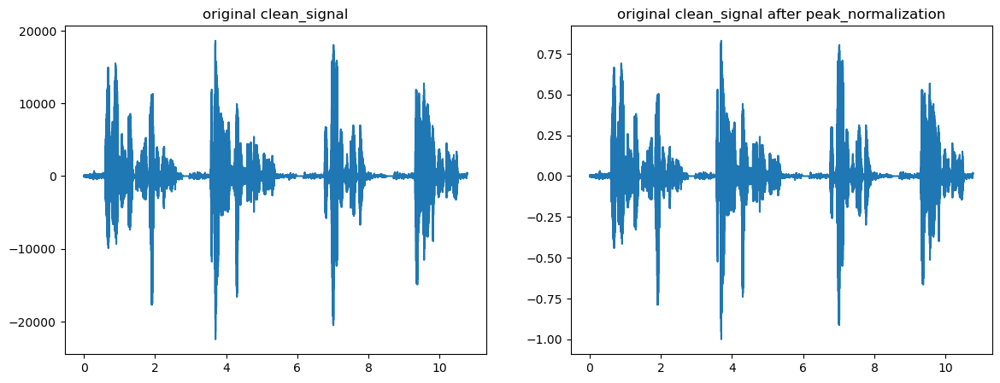

In [226]:
# print(clean)
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1); plt.plot(t_clean, clean_signal); plt.title("original clean_signal")
plt.subplot(1, 2, 2); plt.plot(t_clean, clean); plt.title("original clean_signal after peak_normalization")

# Noise Signal

In [227]:
fs_noise, noise_signal = wavfile.read("./audio/noise_recording.wav")
t_noise = np.arange(len(noise_signal)) / fs_noise

print("fs =",fs_noise)
print("Samples =",len(noise_signal))
print("Duration =",len(noise_signal)/fs_noise,"s")
print("signal shape =", noise_signal.shape) #mono signal, 1 channel
print("signal dtype =", noise_signal.dtype)

fs = 44100
Samples = 587001
Duration = 13.310680272108844 s
signal shape = (587001,)
signal dtype = int16


In [228]:
noise = noise_signal.astype(np.float64)
noise = noise / np.max(np.abs(noise))

Text(0.5, 1.0, 'original noise_signal after peak_normalization')

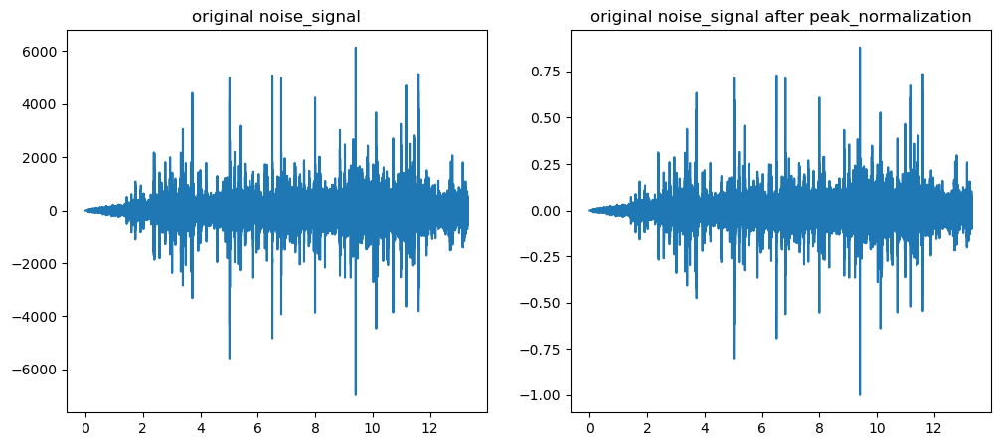

In [229]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1); plt.plot(t_noise, noise_signal); plt.title("original noise_signal")
plt.subplot(1, 2, 2); plt.plot(t_noise, noise); plt.title("original noise_signal after peak_normalization")

# Adding noise to clean signal

In [230]:
noise = noise[fs_noise*2:len(clean)+fs_noise*2]
print(len(noise), len(clean))   # both numbers should be the same

172343 172343


In [231]:
# noise_level = 0.5               # the number that controls how loud the noise is

noisy_speech = clean + noise

Clean


Noisy


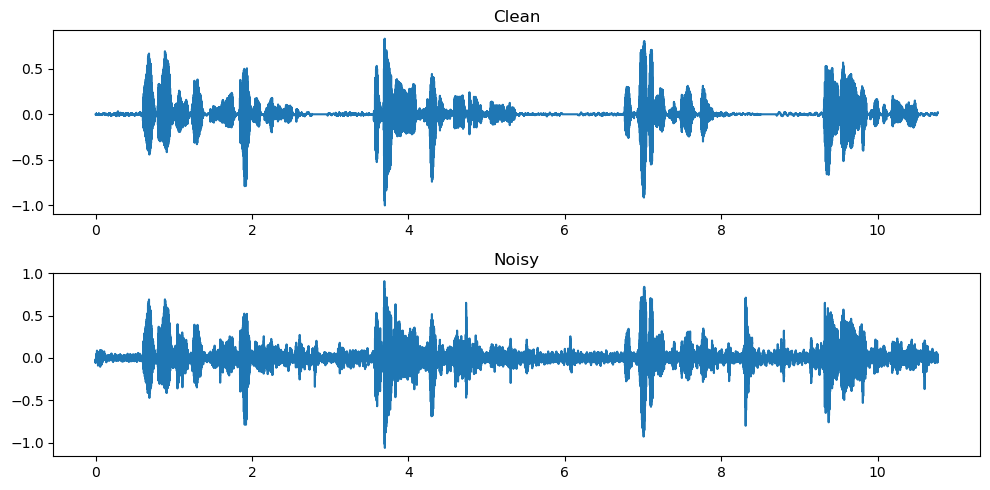

In [232]:
print("Clean")
ipd.display(ipd.Audio(clean, rate=fs_clean))
print("Noisy")
ipd.display(ipd.Audio(noisy_speech, rate=fs_clean))

plt.figure(figsize=(10, 5))
plt.subplot(2, 1, 1); plt.plot(t_clean, clean); plt.title("Clean")
plt.subplot(2, 1, 2); plt.plot(t_clean, noisy_speech); plt.title("Noisy")
plt.tight_layout()
plt.show()

In [233]:
# # save the noisy_speech
# import os
# os.makedirs("./audio/audio_run", exist_ok=True)       # make the folder if it doesn't exist

# noisy_save = noisy_speech / max(1, np.max(np.abs(noisy_speech)))   # only shrinks it if it goes above 1
# wavfile.write("./audio/audio_run/noisy_speech.wav", fs_clean, (noisy_save * 32767).astype(np.int16))

# Audio Noise Reduction

1. EDA

In [234]:
def spectrum(x, fs, nfft = -1):
  N = len(x)
  if nfft == -1:
    nfft = N
  X = np.fft.fft(x, nfft)
  X = X[:N//2]
  mag = np.abs(X) *2/N
  mag[-1] = mag[-1]/2
  mag[0]  = mag[0]/2

  freq = np.arange(len(mag)) * fs/N
  return freq, mag

In [235]:
fs, x = wavfile.read("./audio/audio_run/noisy_speech.wav")
t = np.arange(len(x)) /fs
print("fs noisy: ", fs)

fs noisy:  16000


Text(0, 0.5, 'amplitude')

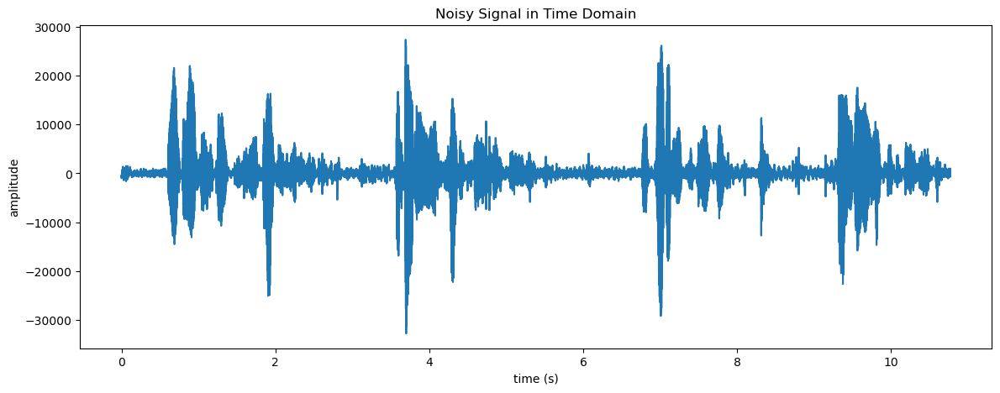

In [236]:
# plot in time domain
plt.figure(figsize=(14, 5))
plt.plot(t, x)
plt.title("Noisy Signal in Time Domain")
plt.xlabel("time (s)")
plt.ylabel("amplitude")

Text(0, 0.5, 'magnitude')

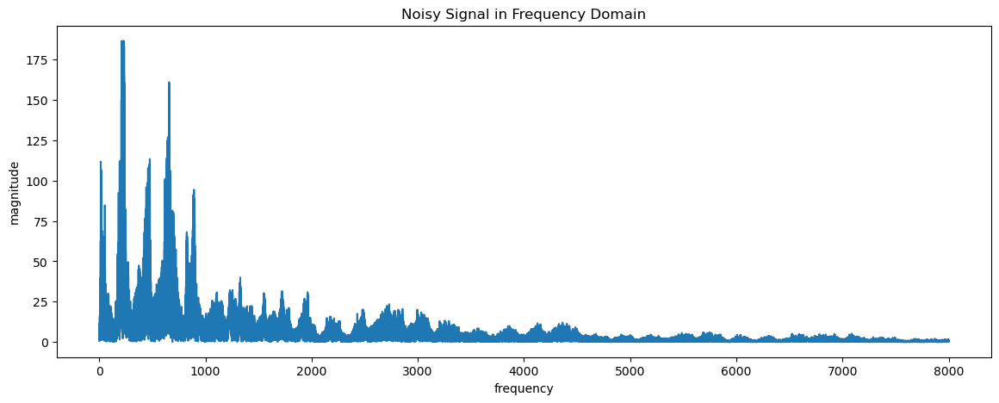

In [237]:
# plot in Frequency Domain
freq, mag = spectrum(x, fs)
plt.figure(figsize=(14, 5))
plt.plot(freq, mag)
plt.title("Noisy Signal in Frequency Domain")
plt.xlabel("frequency")
plt.ylabel("magnitude")

total samples =  172343


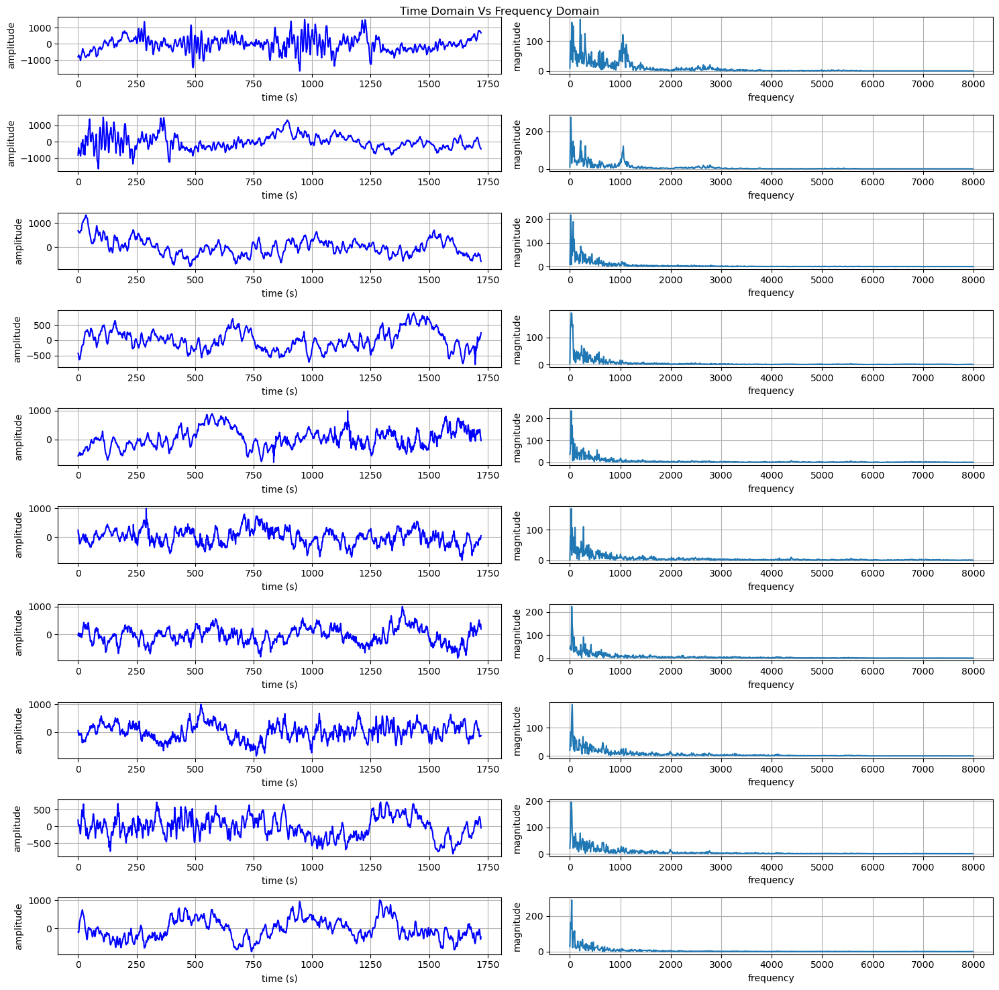

In [238]:
num_frame = 100
total_samples = len(noisy_speech) #N
frame_length = total_samples // num_frame #L
hop = int(0.5*frame_length)

print("total samples = ",total_samples)

p0 = 0
p1 = frame_length

plt.figure(figsize=(15, 15))

index = 1
for i in range(1, 11):
  x_win = x[p0:p1]
  plt.subplot(10, 2, index)
  plt.plot(x_win, color = "b")
  plt.grid()
  plt.xlabel("time (s)")
  plt.ylabel("amplitude")

  index = index + 1
  freq_win, mag_win = spectrum(x_win, fs)
  plt.subplot(10, 2, index)
  plt.plot(freq_win, mag_win)
  plt.xlabel("frequency")
  plt.ylabel("magnitude")
  plt.grid()
  
  p0 += hop
  p1 += hop
  index = index + 1
plt.suptitle("Time Domain Vs Frequency Domain")
plt.tight_layout()

## 1. Strong Low-Frequency Energy (Rumble / Drift)

- **Observation:** Every frame has its largest peak at the far left of the spectrum (~30-250 Hz).
- **Time-Domain Effect:** Waveforms drift above and below the zero line.
- **Diagnosis:** Low-frequency rumble or DC drift, mixed with the speaker's low-pitch content.
- **Required Action:** High-pass filter with a cutoff of ~60-100 Hz, chosen to avoid cutting the speech fundamental.

## 2. Transient Tone near 1000 Hz

- **Observation:** Frames 1-2 show a sharp peak at ~1000-1050 Hz; it is almost gone by frame 3.
- **Diagnosis:** Likely a brief beep at the start of the recording (verify with a spectrogram, since it could be a speech formant).
- **Required Action:** Narrow notch filter at the measured peak frequency.

## 3. Little High-Frequency Energy

- **Observation:** Energy decays steadily above ~2000 Hz and is very small beyond ~4000 Hz, with only minor isolated bumps.
- **Diagnosis:** No significant broadband hiss.
- **Required Action:** A low-pass filter is not needed.

-----------------

# Pipeline

In [239]:
# fs, x

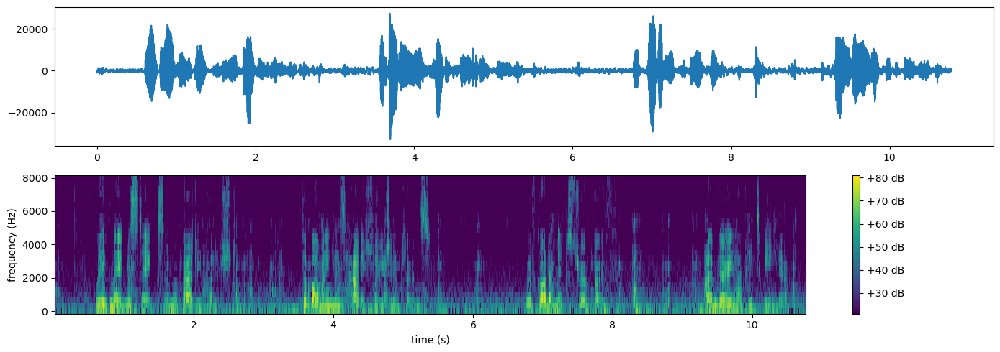

In [240]:
def spectrogram_db(x, fs, L, H, NFFT=None):
    if NFFT is None:
        NFFT = L  # Standard: matches window size L
        
    f_spec, t_spec, Z = signal.stft(
        x, 
        fs, 
        window='hann', 
        nperseg=L, 
        noverlap=L-H, 
        boundary=None, 
        padded=False, 
        nfft=NFFT
    )
    # 1e-10 prevents log10(0) -> -inf
    S_db = 20 * np.log10(np.abs(Z) + 1e-10)
    return f_spec, t_spec, S_db, Z

plt.figure(figsize=(14, 5))

# Subplot 1: Signal plot (using your pre-defined x and t)
plt.subplot(2, 1, 1)
plt.plot(t, x)

# Subplot 2: Spectrogram
L, H = 50, 25  # window length 0.5 s, hop 0.25 s
S_f, S_t, S_db, Z = spectrogram_db(x, fs, L, H)

plt.subplot(2, 1, 2)
plt.pcolormesh(S_t, S_f, S_db, vmin=S_db.max() - 60, shading='nearest')
plt.xlabel("time (s)")
plt.ylabel("frequency (Hz)")
plt.colorbar(format="%+2.0f dB")

plt.tight_layout()
plt.show()

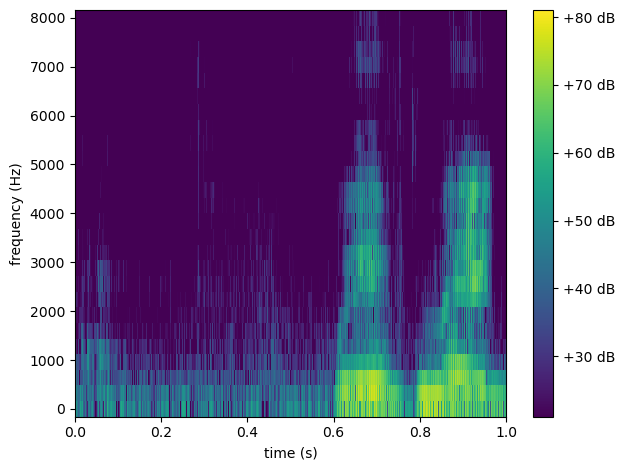

In [241]:
plt.pcolormesh(S_t, S_f, S_db, vmin=S_db.max() - 60, shading="nearest")
plt.xlim(0, 1)
plt.xlabel("time (s)")
plt.ylabel("frequency (Hz)")
plt.colorbar(format="%+2.0f dB")

plt.tight_layout()
plt.show()

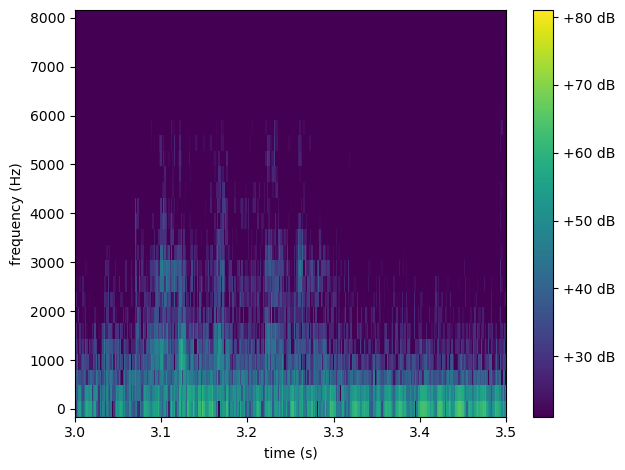

In [242]:
plt.pcolormesh(S_t, S_f, S_db, vmin=S_db.max() - 60, shading="nearest")
plt.xlim(3, 3.5)
plt.xlabel("time (s)")
plt.ylabel("frequency (Hz)")
plt.colorbar(format="%+2.0f dB")

plt.tight_layout()
plt.show()

1. Speech Activity: High vertical bursts of energy with distinct harmonic bands across frequencies (e.g., around $0.6\text{s} - 2.5\text{s}$, $3.6\text{s} - 4.8\text{s}$, and $6.8\text{s} - 8.2\text{s}$).

2. Noise-Only Regions (Pauses): Look at regions where speech stops, such as $0.0\text{s} - 0.5\text{s}$, $5.0\text{s} - 6.5\text{s}$, and $8.2\text{s} - 9.2\text{s}$.

In [243]:
print("=== MATRIX METADATA ===")
print(f"Z Shape (Frequency Bins x Time Frames) : {Z.shape}")
print(f"Total elements                         : {Z.size}")
print(f"Data type                              : {Z.dtype}")
print("-" * 50)

=== MATRIX METADATA ===
Z Shape (Frequency Bins x Time Frames) : (26, 6892)
Total elements                         : 179192
Data type                              : complex64
--------------------------------------------------


In [244]:
print(Z)

[[-6.2702991e+02+0.00000000e+00j -5.3461420e+02+0.00000000e+00j
  -4.3582922e+02+0.00000000e+00j ... -2.3145517e+02+0.00000000e+00j
   6.0415283e+01+0.00000000e+00j  4.2243832e+02+0.00000000e+00j]
 [ 2.6641702e+02-4.55494423e+01j  2.7236551e+02+1.04824745e+02j
   2.4976210e+02-8.69261703e+01j ...  2.9484348e+02+5.52963409e+01j
  -2.3259003e+01-1.37450714e+02j -2.9806509e+02+1.36511581e+02j]
 [ 6.3071918e+01+9.48480148e+01j  3.4366760e+00-3.88511353e+01j
  -4.1268154e+01+1.36707642e+02j ... -2.3064467e+02-6.38496475e+01j
   4.1042070e+00+1.65007339e+02j  9.0624420e+01-3.24457474e+01j]
 ...
 [ 4.7832519e-01+6.81992173e-01j -5.1571959e-01-5.34692347e-01j
  -2.2279297e-01+6.60351515e-02j ...  9.5828122e-01+4.04052734e-01j
   6.5728757e-03-4.51318353e-01j  4.2170897e-01+4.49240714e-01j]
 [-2.2637695e-01-2.45419919e-01j  3.7085935e-01+3.40214849e-01j
   3.5581055e-01-3.19008768e-01j ... -6.3733399e-01-1.78139642e-01j
  -4.6661377e-02+3.91997069e-01j  6.3144527e-02-1.73632801e-02j]
 [ 8.01562

In [245]:
# -------------------------------------------------------------
# 3. Extract Noise Matrix from Z (e.g., using 5.0s to 6.2s pause)
# -------------------------------------------------------------
quiet_mask = (S_t >= 0.0) & (S_t <= 0.6)

# Average noise magnitude profile along frequency bins (Shape: [Frequency Bins, 1])
N_profile = np.mean(np.abs(Z[:, quiet_mask]), axis=1, keepdims=True) 

# Broadcast across time to form the Noise Matrix (Shape: [Frequency Bins, Time Frames])
N_matrix = np.tile(N_profile, (1, Z.shape[1]))

print("Complex STFT Matrix (Z) shape:", Z.shape)
print("Noise Profile Vector shape:", N_profile.shape)
print("Noise Matrix shape:", N_matrix.shape)

Complex STFT Matrix (Z) shape: (26, 6892)
Noise Profile Vector shape: (26, 1)
Noise Matrix shape: (26, 6892)


In [246]:
# Parameters
alpha = 1.5   # Over-subtraction factor (1.0 to 2.0)
beta = 0.02   # Spectral floor factor to prevent musical noise artifacts

# 1. Compute noisy magnitude and phase
noisy_magnitude = np.abs(Z)
phase = np.angle(Z)

# 2. Subtract noise matrix with spectral floor protection
subtracted_magnitude = noisy_magnitude - (alpha * N_matrix)
floor_threshold = beta * noisy_magnitude

# Apply floor so magnitude never drops below beta * noisy_magnitude
clean_magnitude = np.maximum(subtracted_magnitude, floor_threshold)

# 3. Reconstruct complex STFT matrix using original phase
Z_clean = clean_magnitude * np.exp(1j * phase)

# 4. Reconstruct clean time-domain audio signal
_, x_clean = signal.istft(
    Z_clean, 
    fs, 
    window='hann', 
    nperseg=L, 
    noverlap=L-H, 
    boundary=None,
    nfft=L
)

C:\Users\HP\AppData\Local\Temp\ipykernel_23656\870440170.py:20: UserWarning: NOLA condition failed, STFT may not be invertible. Possibly due to missing boundary
  _, x_clean = signal.istft(


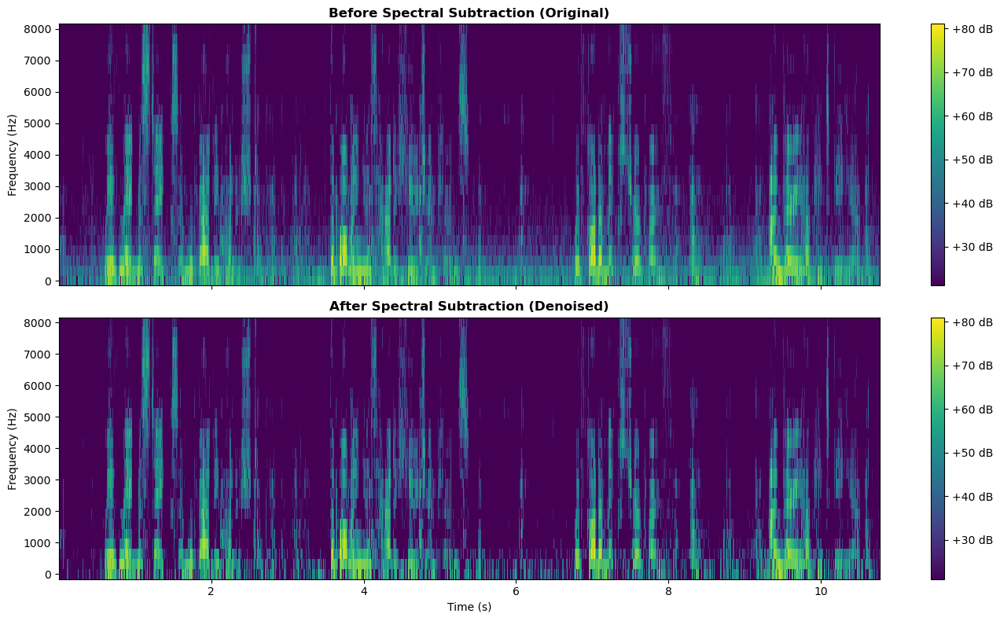

In [247]:
# Compute decibel magnitudes for display
S_db_before = 20 * np.log10(np.abs(Z) + 1e-10)
S_db_after = 20 * np.log10(np.abs(Z_clean) + 1e-10)

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True, sharey=True)

# 1. Before Spectral Subtraction
im1 = axes[0].pcolormesh(S_t, S_f, S_db_before, vmin=S_db_before.max() - 60, shading='nearest')
axes[0].set_title("Before Spectral Subtraction (Original)", fontsize=12, fontweight='bold')
axes[0].set_ylabel("Frequency (Hz)")
fig.colorbar(im1, ax=axes[0], format="%+2.0f dB")

# 2. After Spectral Subtraction
im2 = axes[1].pcolormesh(S_t, S_f, S_db_after, vmin=S_db_before.max() - 60, shading='nearest')
axes[1].set_title("After Spectral Subtraction (Denoised)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Frequency (Hz)")
fig.colorbar(im2, ax=axes[1], format="%+2.0f dB")

plt.tight_layout()
plt.show()

In [248]:
ipd.display(ipd.Audio(data=x, rate=fs))

ipd.display(ipd.Audio(data=x_clean, rate=fs))

In [249]:
print(S_db_before)

[[ 55.945763    54.56081     52.786327   ...  47.289337    35.622936
   52.515266  ]
 [ 48.636368    49.302925    48.447083   ...  49.54196     42.88555
   50.313206  ]
 [ 41.13081     31.821926    43.094604   ...  47.579556    44.352753
   39.668694  ]
 ...
 [ -1.5869794   -2.5816903  -12.676276   ...   0.34051314  -6.909419
   -4.206102  ]
 [ -9.52813     -5.9639425   -6.413653   ...  -3.58597     -8.073239
  -23.67673   ]
 [-21.921251   -13.129982   -19.865334   ... -11.152488   -12.78067
  -12.442554  ]]


In [250]:
print(S_db_after)

[[ 49.09794    45.693962   39.44716   ...  13.3099375   1.6435359
   38.109726 ]
 [ 31.93897    35.719444   30.554081  ...  36.806282    8.906151
   39.743305 ]
 [ 17.46973    -2.1574745  31.21466   ...  42.469696   35.36193
    5.689294 ]
 ...
 [-35.56638   -36.561092  -46.655674  ... -33.638885  -40.88882
  -38.1855   ]
 [-43.50753   -39.943344  -40.39305   ... -37.56537   -42.052643
  -57.65613  ]
 [-55.90065   -47.10938   -53.844734  ... -45.13189   -46.760067
  -46.42195  ]]


In [251]:
# create peak detection

C:\Users\HP\AppData\Local\Temp\ipykernel_23656\3324815143.py:21: UserWarning: NOLA condition failed, STFT may not be invertible. Possibly due to missing boundary
  _, x_transient_removed = signal.istft(


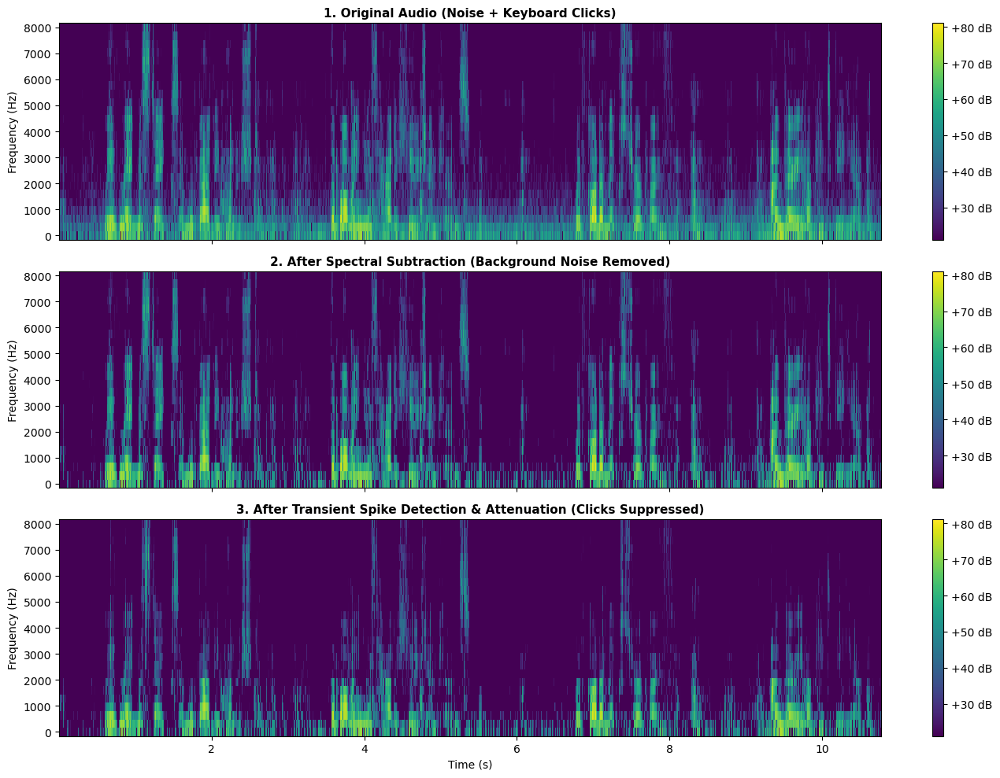

--- AUDIO STAGES ---
1. Original Audio:


2. After Spectral Subtraction (Background Noise Removed):


3. After Transient Spike Attenuation (Clicks Removed):


In [259]:
from scipy.ndimage import median_filter, binary_dilation
# -------------------------------------------------------------
# 1. Transient Spike Detection & Removal on Z_clean
# -------------------------------------------------------------
# Calculate energy per time frame across high frequencies (> 2000 Hz)
frame_energy = np.mean(np.abs(Z_clean[S_f > 2000, :]), axis=0)

# Identify sudden spikes relative to the moving median baseline
moving_med = median_filter(frame_energy, size=41)
# spike_mask = frame_energy > (1.5 * moving_med)
spike_mask_raw = frame_energy > (1.5 * moving_med)
spike_mask = binary_dilation(spike_mask_raw, iterations=1)

# Suppress magnitude in spike frames above 2 kHz by 20 dB (0.1 factor)
Z_transient_removed = Z_clean.copy()
Z_transient_removed[np.ix_(S_f > 2000, spike_mask)] *= 0.1

# -------------------------------------------------------------
# 2. Reconstruct Time-Domain Signals via iSTFT
# -------------------------------------------------------------
_, x_transient_removed = signal.istft(
    Z_transient_removed, 
    fs, 
    window='hann', 
    nperseg=L, 
    noverlap=L-H, 
    boundary=None,
    nfft=L
)

# -------------------------------------------------------------
# 3. Plot Spectrogram Comparison (3 Stages)
# -------------------------------------------------------------
S_db_original = 20 * np.log10(np.abs(Z) + 1e-10)
S_db_subtracted = 20 * np.log10(np.abs(Z_clean) + 1e-10)
S_db_spikes_removed = 20 * np.log10(np.abs(Z_transient_removed) + 1e-10)

vmax = S_db_original.max()
vmin = vmax - 60

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True, sharey=True)

# Stage 1: Original Noisy Audio
im1 = axes[0].pcolormesh(S_t, S_f, S_db_original, vmin=vmin, vmax=vmax, shading='nearest')
axes[0].set_title("1. Original Audio (Noise + Keyboard Clicks)", fontsize=11, fontweight='bold')
axes[0].set_ylabel("Frequency (Hz)")
fig.colorbar(im1, ax=axes[0], format="%+2.0f dB")

# Stage 2: After Spectral Subtraction
im2 = axes[1].pcolormesh(S_t, S_f, S_db_subtracted, vmin=vmin, vmax=vmax, shading='nearest')
axes[1].set_title("2. After Spectral Subtraction (Background Noise Removed)", fontsize=11, fontweight='bold')
axes[1].set_ylabel("Frequency (Hz)")
fig.colorbar(im2, ax=axes[1], format="%+2.0f dB")

# Stage 3: After Spike Detection & Attenuation
im3 = axes[2].pcolormesh(S_t, S_f, S_db_spikes_removed, vmin=vmin, vmax=vmax, shading='nearest')
axes[2].set_title("3. After Transient Spike Detection & Attenuation (Clicks Suppressed)", fontsize=11, fontweight='bold')
axes[2].set_xlabel("Time (s)")
axes[2].set_ylabel("Frequency (Hz)")
fig.colorbar(im3, ax=axes[2], format="%+2.0f dB")

plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# 4. Listen to Audio Output
# -------------------------------------------------------------
print("--- AUDIO STAGES ---")
print("1. Original Audio:")
ipd.display(ipd.Audio(data=x, rate=fs))

print("2. After Spectral Subtraction (Background Noise Removed):")
ipd.display(ipd.Audio(data=x_clean, rate=fs))

print("3. After Transient Spike Attenuation (Clicks Removed):")
ipd.display(ipd.Audio(data=x_transient_removed, rate=fs))

In [256]:
print(f"Spike frames detected: {np.sum(spike_mask)}")

Spike frames detected: 1619


In [ ]:
from scipy.ndimage import median_filter

# 1. Take magnitude of the spectral-subtracted output
mag = np.abs(Z_clean)

# 2. Compute high-frequency energy profile (e.g., above 2000 Hz where keyboard clicks stand out)
hf_bins = S_f > 2000
hf_energy = np.mean(mag[hf_bins, :], axis=0)

# 3. Detect sudden energy jumps relative to a local baseline
local_baseline = median_filter(hf_energy, size=10) # Smooth baseline (~15 frames)
transient_spikes = hf_energy > (1.5 * local_baseline) # Trigger on frames >2x local baseline

# 4. Attenuate detected click frames across high frequencies
clean_mag_no_clicks = mag.copy()
# Suppress the click frames by 80% (0.2 factor) in high frequencies
clean_mag_no_clicks[hf_bins, :][:, transient_spikes] *= 0.2

# 5. Reconstruct complex matrix
Z_transient_removed = clean_mag_no_clicks * np.exp(1j * np.angle(Z_clean))

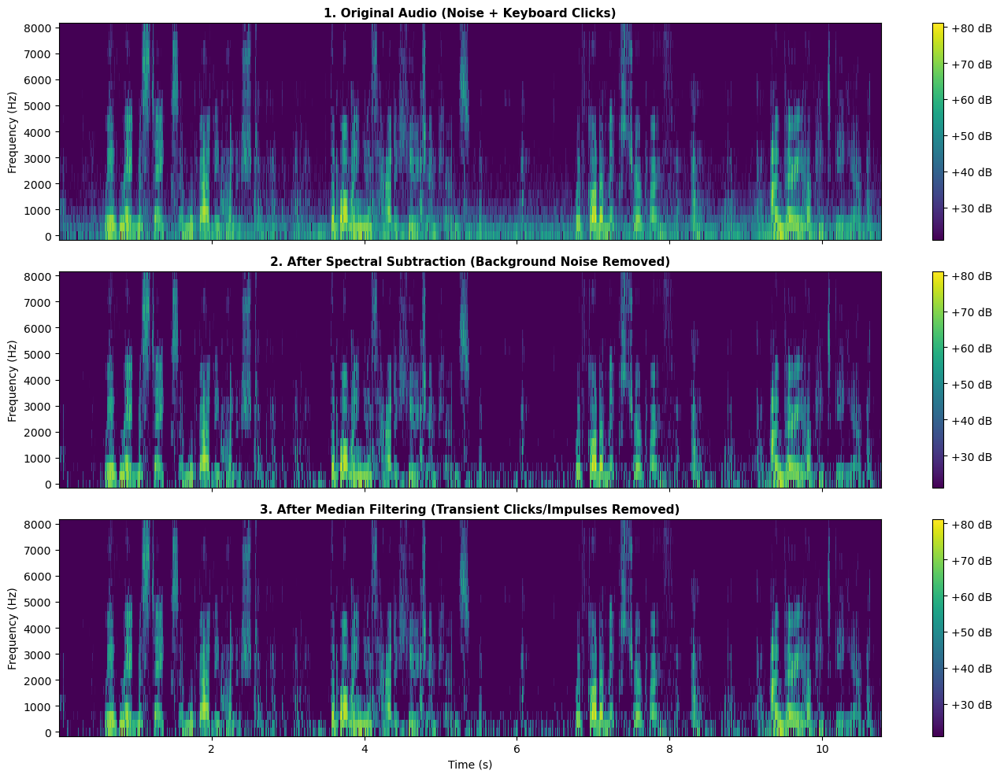

In [ ]:
# 1. Compute decibel magnitudes for all three stages
S_db_original = 20 * np.log10(np.abs(Z) + 1e-10)
S_db_subtracted = 20 * np.log10(np.abs(Z_clean) + 1e-10)
S_db_filtered = 20 * np.log10(np.abs(Z_transient_removed) + 1e-10)

# Dynamic range reference from original
vmax = S_db_original.max()
vmin = vmax - 60

# 2. Plot 3-panel comparison
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True, sharey=True)

# Panel 1: Original Noisy Audio
im1 = axes[0].pcolormesh(S_t, S_f, S_db_original, vmin=vmin, vmax=vmax, shading='nearest')
axes[0].set_title("1. Original Audio (Noise + Keyboard Clicks)", fontsize=11, fontweight='bold')
axes[0].set_ylabel("Frequency (Hz)")
fig.colorbar(im1, ax=axes[0], format="%+2.0f dB")

# Panel 2: After Spectral Subtraction
im2 = axes[1].pcolormesh(S_t, S_f, S_db_subtracted, vmin=vmin, vmax=vmax, shading='nearest')
axes[1].set_title("2. After Spectral Subtraction (Background Noise Removed)", fontsize=11, fontweight='bold')
axes[1].set_ylabel("Frequency (Hz)")
fig.colorbar(im2, ax=axes[1], format="%+2.0f dB")

# Panel 3: After Median Filter
im3 = axes[2].pcolormesh(S_t, S_f, S_db_filtered, vmin=vmin, vmax=vmax, shading='nearest')
axes[2].set_title("3. After Median Filtering (Transient Clicks/Impulses Removed)", fontsize=11, fontweight='bold')
axes[2].set_xlabel("Time (s)")
axes[2].set_ylabel("Frequency (Hz)")
fig.colorbar(im3, ax=axes[2], format="%+2.0f dB")

plt.tight_layout()
plt.show()

In [ ]:
# 1. Reconstruct time-domain signal for Stage 3 (After Median Filter)
_, x_transient_removed = signal.istft(
    Z_transient_removed, 
    fs, 
    window='hann', 
    nperseg=L, 
    noverlap=L-H, 
    boundary=None,
    nfft=L
)

# 2. Display Audio Players for all three stages
print("1. Original Noisy Audio:")
ipd.display(ipd.Audio(data=x, rate=fs))

print("2. After Spectral Subtraction (Background Noise Removed):")
ipd.display(ipd.Audio(data=x_clean, rate=fs))

print("3. After Median Filtering (Transient Clicks Removed):")
ipd.display(ipd.Audio(data=x_transient_removed, rate=fs))

1. Original Noisy Audio:


C:\Users\HP\AppData\Local\Temp\ipykernel_23656\409070868.py:2: UserWarning: NOLA condition failed, STFT may not be invertible. Possibly due to missing boundary
  _, x_transient_removed = signal.istft(


2. After Spectral Subtraction (Background Noise Removed):


3. After Median Filtering (Transient Clicks Removed):


In [ ]:
# --- 1. Define Filter Parameters ---
low_cutoff = 80.0    # Hz (Removes the DC offset and rumble)
high_cutoff = 4000.0 # Hz (Removes the high-frequency hiss)
filter_order = 4     # 4th-order provides a sharp enough cutoff without instability

# Scipy requires normalized frequencies between 0 and 1 (where 1 is the Nyquist frequency)
nyquist = 0.5 * fs
low = low_cutoff / nyquist
high = high_cutoff / nyquist

# --- 2. Design the Filter ---
# b and a are the feedback and feedforward coefficients of the IIR filter
b, a = signal.butter(filter_order, [low, high], btype='bandpass')

# --- 3. Apply the Filter ---
# filtfilt ensures the filtered audio stays perfectly aligned with the original time-wise
filtered_speech = signal.filtfilt(b, a, x)

# --- 4. Prevent Clipping on Output ---
# Filtering can occasionally push transient peaks slightly higher
if np.max(np.abs(filtered_speech)) > 1.0:
    filtered_speech = filtered_speech / np.max(np.abs(filtered_speech))

In [ ]:
# 1. Calculate the noise left in the signals
original_noise_error = noisy_speech - clean
remaining_noise_error = filtered_speech - clean

# 2. Calculate powers
power_clean = np.mean(clean ** 2)
power_orig_error = np.mean(original_noise_error ** 2)
power_rem_error = np.mean(remaining_noise_error ** 2)

# 3. Calculate SNR in Decibels (dB)
snr_before = 10 * np.log10(power_clean / power_orig_error)
snr_after = 10 * np.log10(power_clean / power_rem_error)

snr_improvement = snr_after - snr_before

print(f"SNR Before Filtering: {snr_before:.2f} dB")
print(f"SNR After Filtering:  {snr_after:.2f} dB")
print(f"Net Improvement:      +{snr_improvement:.2f} dB")

SNR Before Filtering: 5.16 dB
SNR After Filtering:  12.39 dB
Net Improvement:      +7.23 dB


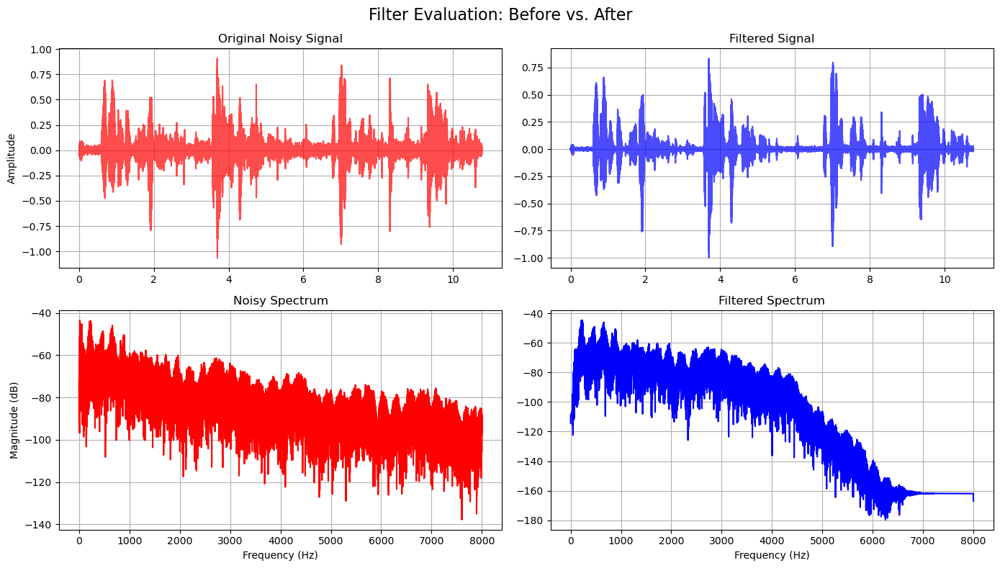

In [ ]:
# Using the spectrum function you defined earlier
freq_noisy, mag_noisy = spectrum(noisy_speech, fs)
freq_clean, mag_clean = spectrum(filtered_speech, fs)

# Convert to dB for visibility
mag_noisy_db = 20 * np.log10(mag_noisy + 1e-9)
mag_clean_db = 20 * np.log10(mag_clean + 1e-9)

time_axis = np.arange(len(noisy_speech)) / fs

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
fig.suptitle("Filter Evaluation: Before vs. After", fontsize=16)

# --- Top Left: Noisy Time Domain ---
axes[0, 0].plot(time_axis, noisy_speech, color='red', alpha=0.7)
axes[0, 0].set_title("Original Noisy Signal")
axes[0, 0].set_ylabel("Amplitude")
axes[0, 0].grid(True)

# --- Top Right: Clean Time Domain ---
axes[0, 1].plot(time_axis, filtered_speech, color='blue', alpha=0.7)
axes[0, 1].set_title("Filtered Signal")
axes[0, 1].grid(True)

# --- Bottom Left: Noisy Frequency Domain ---
axes[1, 0].plot(freq_noisy, mag_noisy_db, color='red')
axes[1, 0].set_title("Noisy Spectrum")
axes[1, 0].set_xlabel("Frequency (Hz)")
axes[1, 0].set_ylabel("Magnitude (dB)")
axes[1, 0].grid(True)

# --- Bottom Right: Clean Frequency Domain ---
axes[1, 1].plot(freq_clean, mag_clean_db, color='blue')
axes[1, 1].set_title("Filtered Spectrum")
axes[1, 1].set_xlabel("Frequency (Hz)")
axes[1, 1].grid(True)

plt.tight_layout()
plt.show()

In [ ]:
ipd.display(ipd.Audio(data=x, rate=fs))

ipd.display(ipd.Audio(data=filtered_speech, rate=fs))

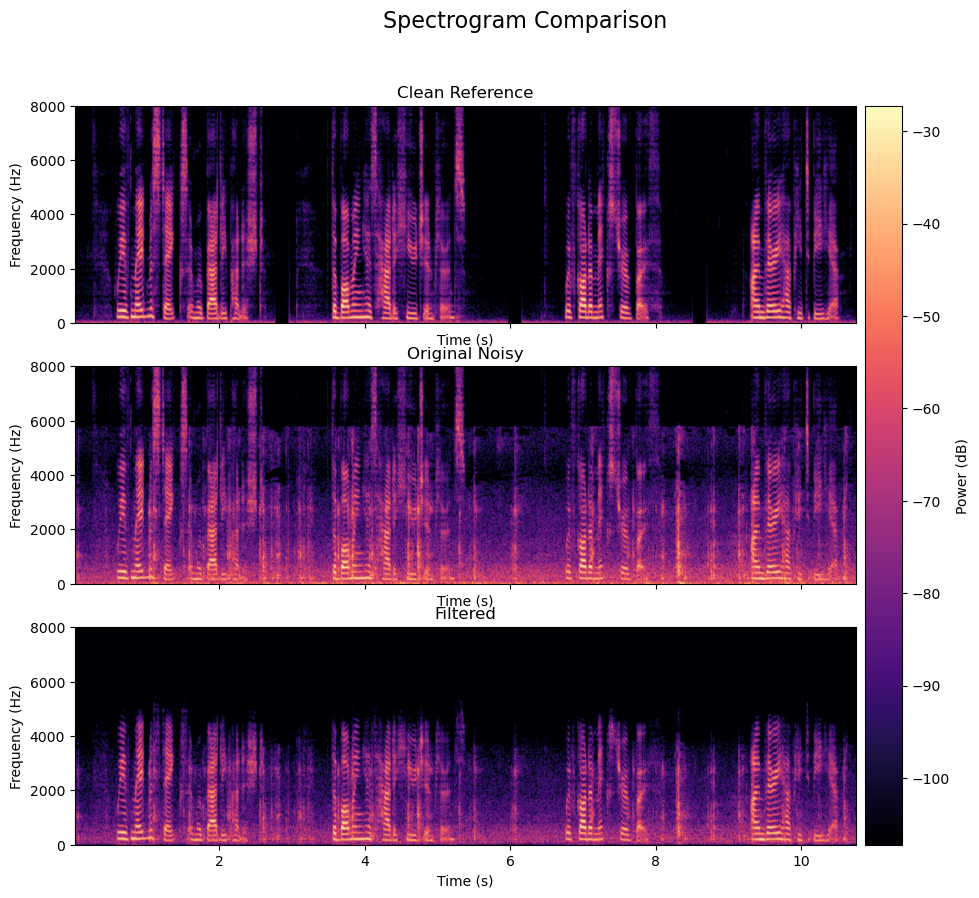

In [ ]:
def plot_spectrogram(ax, x, fs, title, vmin, vmax):
    f, t, Sxx = signal.spectrogram(
        np.asarray(x, dtype=np.float64), fs=fs,
        window='hann', nperseg=512, noverlap=384, mode='psd'
    )
    Sxx_db = 10 * np.log10(Sxx + 1e-12)
    im = ax.pcolormesh(t, f, Sxx_db, shading='gouraud',
                       cmap='magma', vmin=vmin, vmax=vmax)
    ax.set_title(title)
    ax.set_ylabel("Frequency (Hz)")
    ax.set_xlabel("Time (s)")
    return im

signals = [
    ("Clean Reference", clean),
    ("Original Noisy", noisy_speech),
    ("Filtered", filtered_speech),
]

# Shared color scale: top 80 dB below the loudest point of the clean signal
_, _, S = signal.spectrogram(np.asarray(clean, dtype=np.float64),
                             fs=fs, nperseg=512, noverlap=384)
vmax = 10 * np.log10(S.max())
vmin = vmax - 80

fig, axes = plt.subplots(len(signals), 1, figsize=(12, 3.2 * len(signals)),
                         sharex=True, sharey=True)
for ax, (name, x) in zip(axes, signals):
    im = plot_spectrogram(ax, x, fs, name, vmin, vmax)

fig.colorbar(im, ax=axes, label="Power (dB)", pad=0.01)
plt.suptitle("Spectrogram Comparison", fontsize=16)
plt.show()

In [ ]:
# --- 1. Compute the STFT ---
# Convert the Phase 1 filtered audio into overlapping frequency frames
f, t, Zxx = signal.stft(filtered_speech, fs=fs, window='hann', nperseg=1024, noverlap=512)

# Separate into Magnitude (volume) and Phase (timing)
mag = np.abs(Zxx)
phase = np.angle(Zxx)

# --- 2. Estimate the Noise Profile ---
# We assume the first 0.25 seconds is just background noise, no speech
time_res = t[1] - t[0]
noise_frames = int(0.25 / time_res)

# Average those early frames to create a "fingerprint" of the remaining noise
noise_profile = np.mean(mag[:, :noise_frames], axis=1, keepdims=True)

# --- 3. Spectral Subtraction (The Fine-Tuning Stage) ---
# Hyperparameters for the experiment:
alpha = 2.5  # Over-subtraction factor: How aggressively to pull down the noise
beta = 0.05  # Spectral floor: Leaves 5% of noise to mask underwater/robotic artifacts

clean_mag = mag - (alpha * noise_profile)
clean_mag = np.maximum(clean_mag, beta * noise_profile) # Apply the floor limit

# --- 4. Reconstruct the Signal ---
# Staple the untouched phase back onto our cleaned magnitude
Zxx_clean = clean_mag * np.exp(1j * phase)

# Inverse STFT to generate the final Phase 2 audio
_, phase2_speech = signal.istft(Zxx_clean, fs=fs, window='hann', nperseg=1024, noverlap=512)

# Prevent length mismatch errors caused by STFT padding
phase2_speech = phase2_speech[:len(clean)]

# --- 5. Evaluate the 2-Stage Pipeline ---
noise_after_phase2 = phase2_speech - clean
power_noise_phase2 = np.mean(noise_after_phase2 ** 2)
snr_phase2 = 10 * np.log10(power_clean / power_noise_phase2)

print(f"SNR After Phase 1 (Band-Pass): {snr_after:.2f} dB")
print(f"SNR After Phase 2 (STFT):      {snr_phase2:.2f} dB")
print(f"Total Pipeline Improvement:    +{(snr_phase2 - snr_before):.2f} dB")

SNR After Phase 1 (Band-Pass): 12.39 dB
SNR After Phase 2 (STFT):      13.44 dB
Total Pipeline Improvement:    +8.28 dB


In [ ]:
print("1. Ground Truth (Original Clean Audio):")
ipd.display(ipd.Audio(data=clean_signal, rate=fs))

print("2. Corrupted (Noisy Audio):")
ipd.display(ipd.Audio(data=noisy_speech, rate=fs))

print("3. Phase 1 (Band-Pass Filtered):")
ipd.display(ipd.Audio(data=filtered_speech, rate=fs))

print("4. Phase 2 (STFT Spectral Subtraction):")
ipd.display(ipd.Audio(data=phase2_speech, rate=fs))

1. Ground Truth (Original Clean Audio):


2. Corrupted (Noisy Audio):


3. Phase 1 (Band-Pass Filtered):


4. Phase 2 (STFT Spectral Subtraction):


In [ ]:
print("Clean max:", np.max(np.abs(clean)))
print("Phase 2 max:", np.max(np.abs(phase2_speech)))

Clean max: 1.0
Phase 2 max: 0.935046856362878


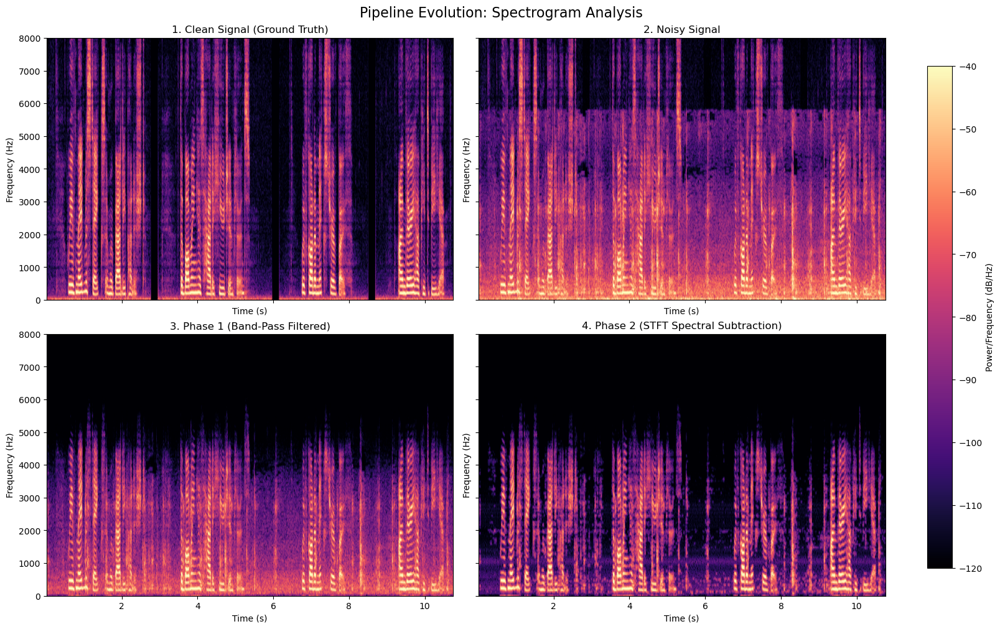

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10),
                         sharex=True, sharey=True,
                         layout='constrained')
fig.suptitle("Pipeline Evolution: Spectrogram Analysis", fontsize=16)

v_min, v_max = -120, -40

im1 = plot_spectrogram(axes[0, 0], clean,           fs, "1. Clean Signal (Ground Truth)",        v_min, v_max)
im2 = plot_spectrogram(axes[0, 1], noisy_speech,    fs, "2. Noisy Signal",                       v_min, v_max)
im3 = plot_spectrogram(axes[1, 0], filtered_speech, fs, "3. Phase 1 (Band-Pass Filtered)",       v_min, v_max)
im4 = plot_spectrogram(axes[1, 1], phase2_speech,   fs, "4. Phase 2 (STFT Spectral Subtraction)", v_min, v_max)

fig.colorbar(im4, ax=axes, label="Power/Frequency (dB/Hz)", shrink=0.9)

plt.show()

In [ ]:
# --- 1. Compute the STFT directly on the noisy 'x' ---
f, t, Zxx = signal.stft(x, fs=fs, window='hann', nperseg=1024, noverlap=512)

# Separate into Magnitude (volume) and Phase (timing)
mag = np.abs(Zxx)
phase = np.angle(Zxx)

# --- 2. Estimate the Noise Profile ---
time_res = t[1] - t[0]
noise_frames = int(0.25 / time_res)

# Average those early frames to create a "fingerprint" of the noise
noise_profile = np.mean(mag[:, :noise_frames], axis=1, keepdims=True)

# --- 3. Spectral Subtraction (1-Stage Approach) ---
alpha = 5     # Over-subtraction factor
beta = 0.05   # Spectral floor

clean_mag = mag - (alpha * noise_profile)
clean_mag = np.maximum(clean_mag, beta * noise_profile) # Apply the floor limit

# --- 4. Reconstruct the Signal ---
Zxx_clean = clean_mag * np.exp(1j * phase)
_, no_filter_speech = signal.istft(Zxx_clean, fs=fs, window='hann', nperseg=1024, noverlap=512)

# Prevent length mismatch errors
no_filter_speech = no_filter_speech[:len(clean)]

# --- 5. Evaluate the 1-Stage Pipeline (FIXED SCALING) ---
# Scale 'clean' to float so it matches no_filter_speech
clean_float = clean / 32767.0

noise_no_filter = no_filter_speech - clean_float
power_noise_no_filter = np.mean(noise_no_filter ** 2)

power_clean_float = np.mean(clean_float ** 2)
snr_no_filter = 10 * np.log10(power_clean_float / power_noise_no_filter)

print(f"SNR for 1-Stage Pipeline (STFT Only): {snr_no_filter:.2f} dB")

SNR for 1-Stage Pipeline (STFT Only): -89.20 dB


In [ ]:
print("1. Ground Truth (Original Clean Audio):")
ipd.display(ipd.Audio(data=clean_signal, rate=fs))

print("2. Corrupted (Noisy Audio):")
ipd.display(ipd.Audio(data=noisy_speech, rate=fs))


print("4. Phase 2 (STFT Spectral Subtraction):")
ipd.display(ipd.Audio(data=no_filter_speech, rate=fs))

1. Ground Truth (Original Clean Audio):


2. Corrupted (Noisy Audio):


4. Phase 2 (STFT Spectral Subtraction):


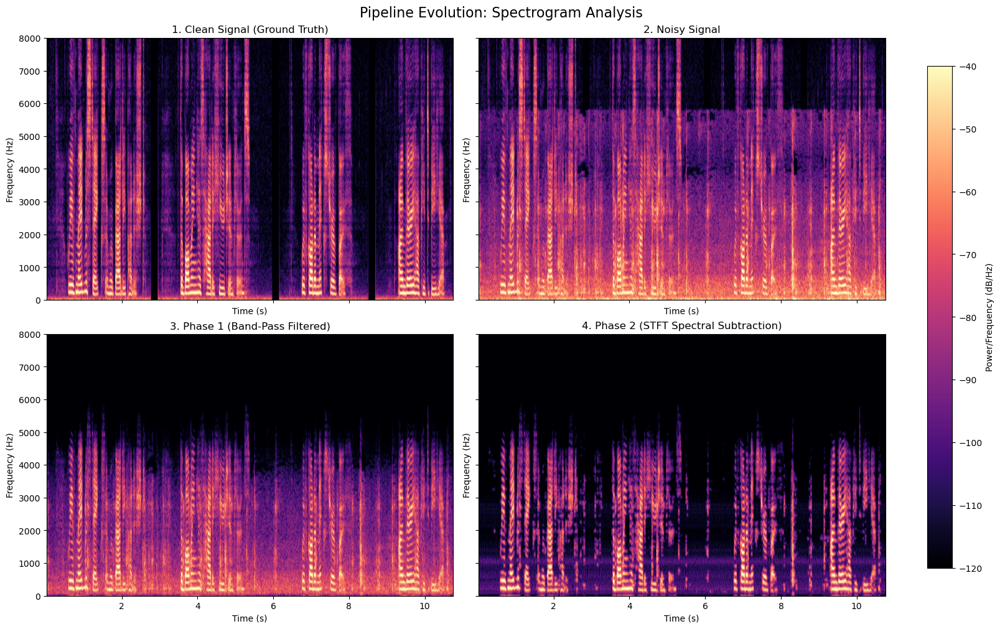

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10),
                         sharex=True, sharey=True,
                         layout='constrained')
fig.suptitle("Pipeline Evolution: Spectrogram Analysis", fontsize=16)

v_min, v_max = -120, -40

im1 = plot_spectrogram(axes[0, 0], clean,           fs, "1. Clean Signal (Ground Truth)",        v_min, v_max)
im2 = plot_spectrogram(axes[0, 1], noisy_speech,    fs, "2. Noisy Signal",                       v_min, v_max)
im3 = plot_spectrogram(axes[1, 0], filtered_speech, fs, "3. Phase 1 (Band-Pass Filtered)",       v_min, v_max)
im4 = plot_spectrogram(axes[1, 1], no_filter_speech,   fs, "4. Phase 2 (STFT Spectral Subtraction)", v_min, v_max)

fig.colorbar(im4, ax=axes, label="Power/Frequency (dB/Hz)", shrink=0.9)

plt.show()